# Module H: analysis of the QuickDraw-100 identifier (Module A)
Inputs from Module A: **`quickdraw100.npz`** (the 600,000 drawings) and **`module_a.pt`** (the trained model). The split is rebuilt exactly as Module A built it, so the test drawings are the ones the model never saw.

Contents: **EDA** (class balance, leakage, empty drawings, size / position / ink statistics, class prototypes, which classes look alike), **metrics** (top-1/3/5/10, macro-F1, kappa, MCC, AUC, log-loss, calibration with bootstrap CIs), **TP / FP / FN / TN for all 100 classes**, **confusion analysis**, ROC / PR, temperature scaling, accuracy-versus-coverage, **regression** (what makes a class or a drawing hard), **robustness without retraining** (shift, rotation, noise, thickness, scale, resolution, dropout) and a **sparse-dot psychometric curve** that connects Module A to the prosthetic-vision question, plus failure galleries.

**Nothing repeats and nothing is trained:** the model is loaded, the test logits, image features and robustness results are cached in `analysis_H_quickdraw/` (tied to the model's id, so a retrained model never reuses old results) and kept in memory.

In [1]:
import os, sys, json, time, math, hashlib, subprocess, warnings
import numpy as np
def need(mod, pip=None):
    try: __import__(mod)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip or mod])
for m, p in (("torch", None), ("pandas", None), ("scipy", None), ("sklearn", "scikit-learn"), ("matplotlib", None)): need(m, p)
import torch, torch.nn as nn, torch.nn.functional as F, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.optimize import minimize, minimize_scalar
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef
warnings.filterwarnings("ignore"); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
# ---- keep-in-memory helper: an object is built once per kernel; re-running a cell re-uses it ----
_mem = globals().setdefault("_mem", {})
def once(name, key, build, verbose=True):
    if name in globals() and _mem.get(name) == key:
        if verbose: print(f"[memory] {name}: already loaded, nothing recomputed")
        return globals()[name]
    globals()[name] = build(); _mem[name] = key; return globals()[name]


In [2]:
# ======== settings: inputs come from Module A ========
CACHE, CKPT, SEED = "quickdraw100.npz", "module_a.pt", 0      # the dataset cache and the trained model written by the Module A notebook (SEED must be the one used there)
OUT_H  = "analysis_H_quickdraw"; os.makedirs(OUT_H, exist_ok=True)
BOOT   = 1000                  # bootstrap resamples
N_ROB  = 3000                  # test images used for each robustness setting
dev = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
for f in (CACHE, CKPT): assert os.path.exists(f), f"{f} not found: run the Module A notebook first and keep this notebook in the same folder"
MID = hashlib.md5(open(CKPT, "rb").read()).hexdigest()[:8]      # id of the trained model: caches are tied to it, so retraining Module A never reuses stale results
KEY = (CACHE, CKPT, SEED, MID, os.path.getsize(CACHE)); print("device:", dev, "| model id:", MID, "| outputs in", OUT_H)

def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
class Net(nn.Module):                                           # identical to Module A
    def __init__(s, n):
        super().__init__()
        s.f = nn.Sequential(block(1, 32), block(32, 32), nn.MaxPool2d(2), block(32, 64), block(64, 64), nn.MaxPool2d(2), block(64, 128), block(128, 128), nn.MaxPool2d(2), block(128, 256))
        s.head = nn.Sequential(nn.Dropout(.3), nn.Linear(256, n))
    def forward(s, x): return s.head(s.f(x).mean((2, 3)))


device: cpu | model id: d10a83e0 | outputs in analysis_H_quickdraw


## 1. Load Module A's data and model; reproduce its test result

In [3]:
# ---------- load Module A's dataset and model ONCE (kept in memory); the split is rebuilt exactly as Module A built it ----------
def build_data():
    d = np.load(CACHE); X, y = d["X"], d["y"]; p = torch.randperm(len(y), generator=torch.Generator().manual_seed(SEED)).numpy(); n5 = len(y) // 20
    return dict(X=X, y=y, te=p[:n5], va=p[n5:2 * n5], tr=p[2 * n5:])
def build_model():
    ck = torch.load(CKPT, map_location=dev); net = Net(len(ck["classes"])).to(dev); net.load_state_dict(ck["state_dict"]); net.eval(); return net, ck["classes"]
DATA = once("DATA", KEY, build_data); NET = once("NET", KEY, build_model); net, CLASSES = NET; NC = len(CLASSES); X, y = DATA["X"], DATA["y"]; te, va, tr = DATA["te"], DATA["va"], DATA["tr"]
assert y.max() + 1 == NC, "dataset and model disagree on the number of classes"
split = np.empty(len(y), "<U5"); split[tr], split[va], split[te] = "train", "val", "test"
print(f"{len(y):,} drawings, {NC} classes | train {len(tr):,} / val {len(va):,} / test {len(te):,}")

@torch.no_grad()
def logits_of(Xu8, bs=2048):
    return torch.cat([net(torch.from_numpy(Xu8[i:i + bs]).to(dev).float().div(255).view(-1, 1, 28, 28)).float().cpu() for i in range(0, len(Xu8), bs)]).numpy()
def softmax(l): e = np.exp(l - l.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
def build_logits():
    f = f"{OUT_H}/logits_{MID}.npz"
    if os.path.exists(f): z = np.load(f); print("logits: loaded", f, "(no inference repeated)"); return {k: z[k] for k in z.files}
    t0 = time.time(); z = {"te": logits_of(X[te]), "va": logits_of(X[va])}; np.savez_compressed(f, **z); print(f"logits computed for val+test in {time.time() - t0:.0f}s -> {f}"); return z
LG = once("LG", KEY, build_logits); yte, yva = y[te], y[va]; Pte, Pva = softmax(LG["te"]), softmax(LG["va"]); pred = Pte.argmax(1)
print(f"model reproduces Module A's test result: top-1 {np.mean(pred == yte):.2%} | top-5 {np.mean((Pte.argsort(1)[:, -5:] == yte[:, None]).any(1)):.2%}")


600,000 drawings, 100 classes | train 540,000 / val 30,000 / test 30,000
logits: loaded analysis_H_quickdraw/logits_d10a83e0.npz (no inference repeated)
model reproduces Module A's test result: top-1 82.67% | top-5 95.41%


## 2. EDA

image features: loaded analysis_H_quickdraw/imgfeat_600000.npz
images per class (min / median / max): {'train': (5348, 5398, 5454), 'val': (255, 301, 345), 'test': (266, 301, 346)}
is the test split balanced across classes? chi-square p = 0.640 (random split: expected counts differ only by chance)
exact duplicate drawings: 11 | identical drawing in BOTH train and test (leakage): 1
near-empty drawings (<1% ink): 3 (0.00%)


,count,mean,std,min,25%,50%,75%,max
ink,600000.0,133.15,44.36,3.25,101.47,126.31,157.69,523.96
cover,600000.0,0.23,0.07,0.01,0.17,0.22,0.27,0.71
bbox_h,600000.0,21.35,5.52,2.00,18.00,24.00,26.00,26.00
bbox_w,600000.0,22.14,5.53,2.00,19.00,26.00,26.00,26.00
bbox_area,600000.0,455.06,131.14,40.00,364.00,468.00,572.00,676.00
fill,600000.0,0.41,0.11,0.01,0.33,0.40,0.48,1.00
off_x,600000.0,-0.07,0.95,-9.54,-0.55,-0.06,0.40,9.63
off_y,600000.0,-0.03,1.27,-9.05,-0.71,-0.01,0.67,8.17
edge,600000.0,173.00,52.14,9.52,135.53,169.55,206.33,407.77


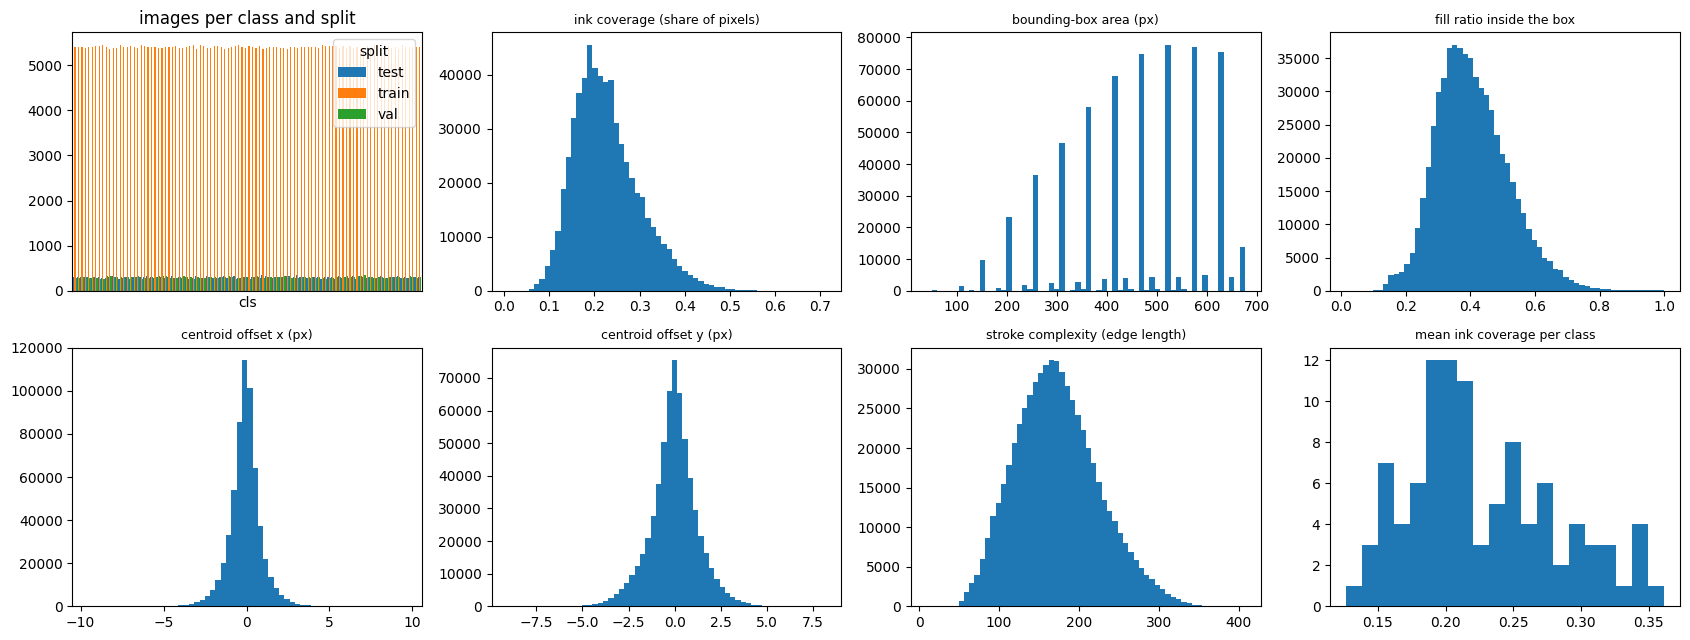

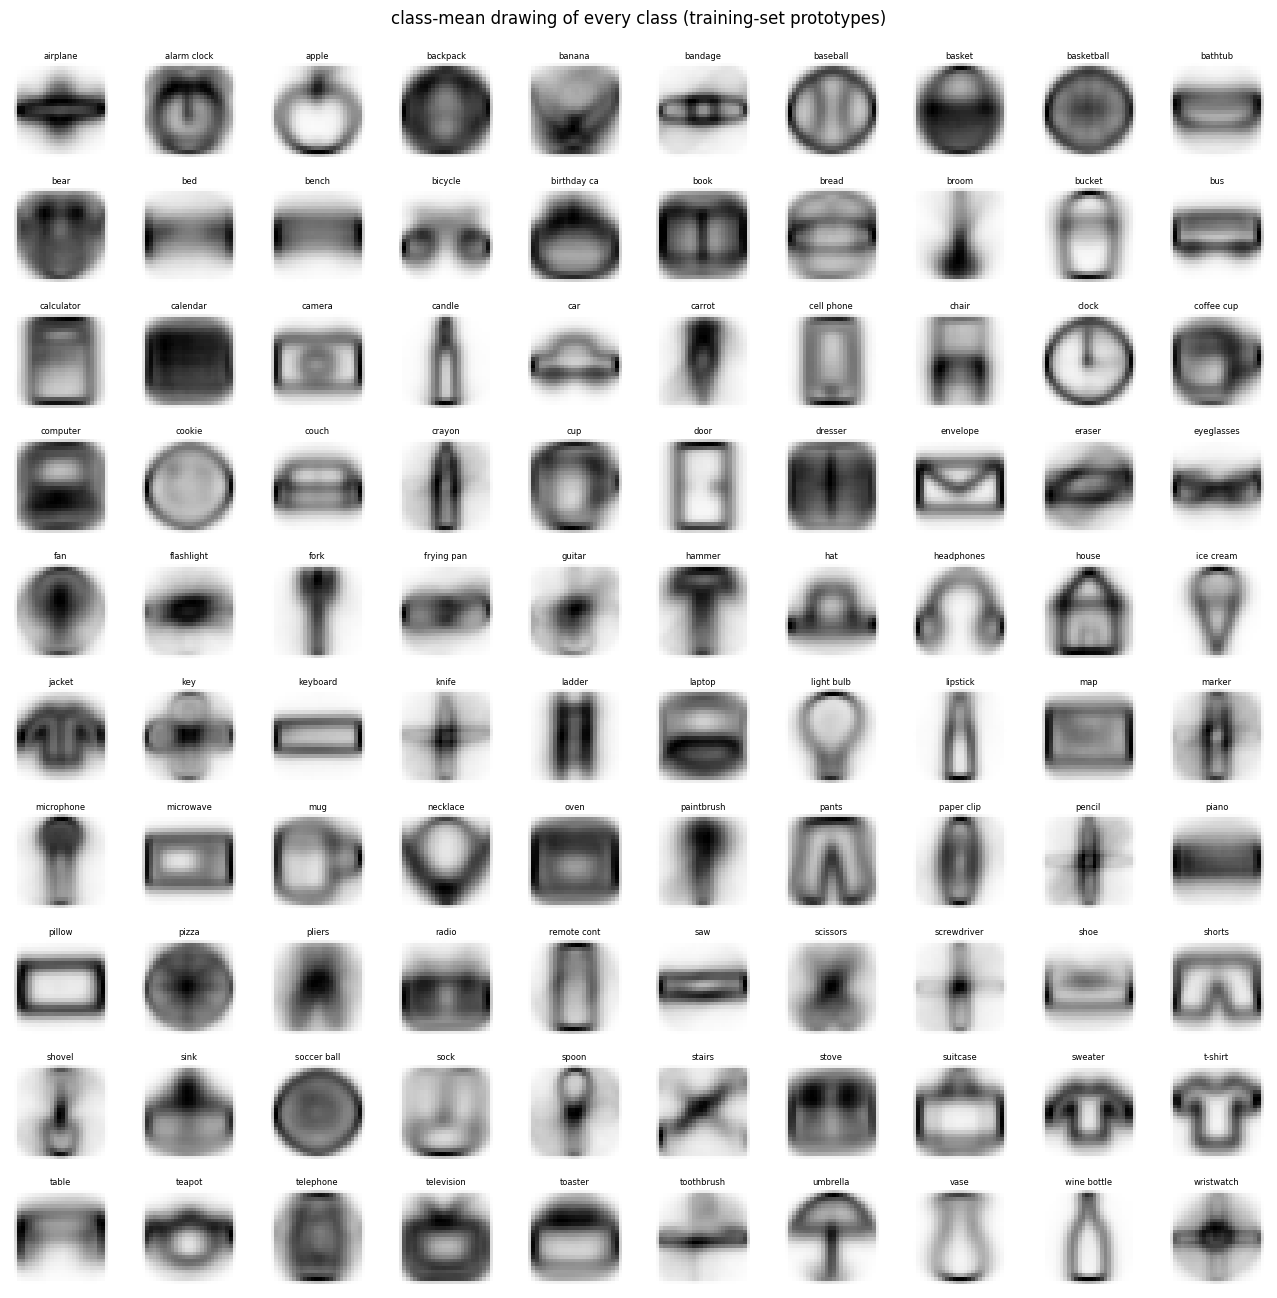

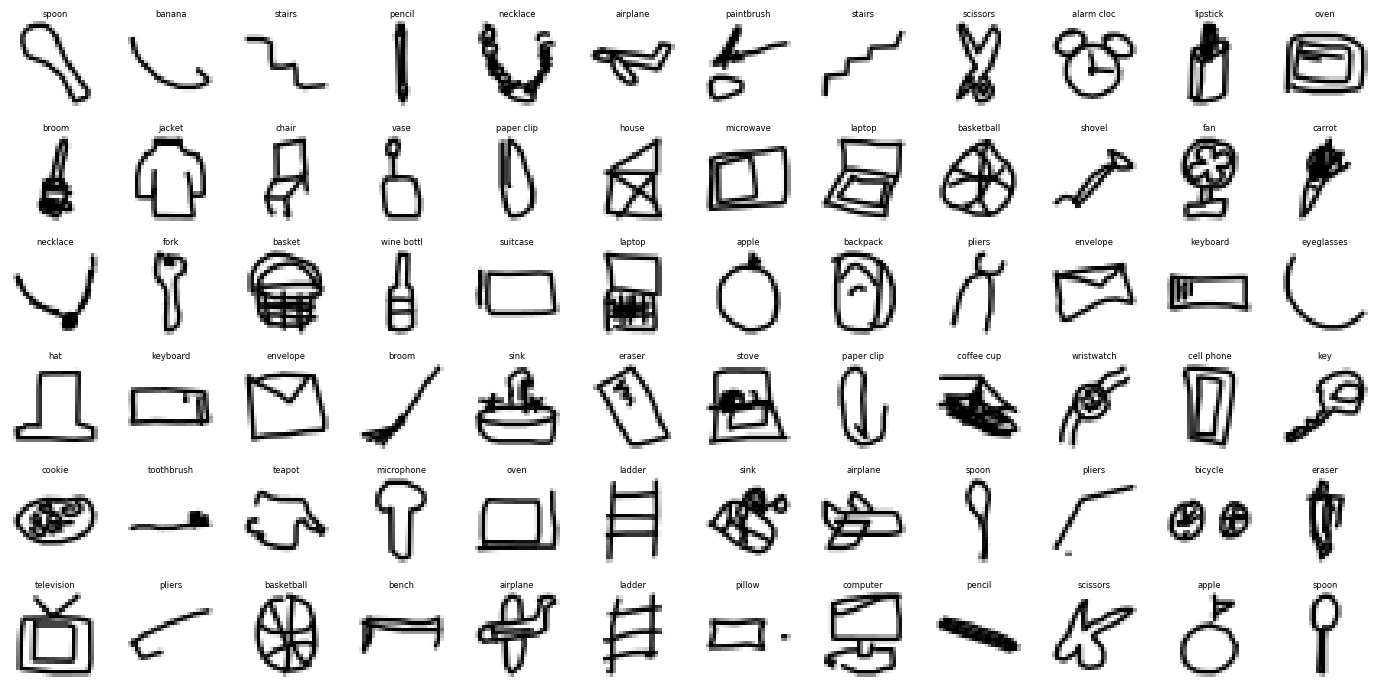

In [4]:
# ---------- EDA 1: class balance, leakage, empty drawings, size / position / ink statistics ----------
def img_feats(Xu8):
    out = []; yy, xx = np.mgrid[0:28, 0:28]
    for i in range(0, len(Xu8), 50000):
        im = Xu8[i:i + 50000].reshape(-1, 28, 28).astype(np.float32) / 255; on = im > .2; rows, cols = on.any(2), on.any(1)
        r0, c0 = rows.argmax(1), cols.argmax(1); r1, c1 = 27 - rows[:, ::-1].argmax(1), 27 - cols[:, ::-1].argmax(1); h, w = (r1 - r0 + 1) * rows.any(1), (c1 - c0 + 1) * cols.any(1)
        ink = im.sum((1, 2)); cx = (im * xx).sum((1, 2)) / np.maximum(ink, 1e-6) - 13.5; cy = (im * yy).sum((1, 2)) / np.maximum(ink, 1e-6) - 13.5
        out.append(np.c_[ink, on.mean((1, 2)), h, w, h * w, on.sum((1, 2)) / np.maximum(h * w, 1), cx, cy, np.abs(np.diff(im, axis=2)).sum((1, 2)) + np.abs(np.diff(im, axis=1)).sum((1, 2))])
    return np.vstack(out)
FCOLS = ["ink", "cover", "bbox_h", "bbox_w", "bbox_area", "fill", "off_x", "off_y", "edge"]
def build_feats():
    f = f"{OUT_H}/imgfeat_{len(y)}.npz"
    if os.path.exists(f): print("image features: loaded", f); return np.load(f)["f"]
    t0 = time.time(); a = img_feats(X); np.savez_compressed(f, f=a); print(f"image features computed in {time.time() - t0:.0f}s"); return a
IF = once("IF", KEY, build_feats); DF = pd.DataFrame(IF, columns=FCOLS); DF["cls"] = y; DF["split"] = split
cnt = pd.crosstab(DF.cls, DF.split); print("images per class (min / median / max):", {s: (int(cnt[s].min()), int(cnt[s].median()), int(cnt[s].max())) for s in ("train", "val", "test")})
chi = stats.chisquare(cnt["test"]); print(f"is the test split balanced across classes? chi-square p = {chi.pvalue:.3f} (random split: expected counts differ only by chance)")
hsh = np.array([hash(r.tobytes()) for r in X]); u, c = np.unique(hsh, return_counts=True)
print(f"exact duplicate drawings: {int((c[c > 1] - 1).sum()):,} | identical drawing in BOTH train and test (leakage): {len(set(hsh[tr]) & set(hsh[te])):,}")
empty = DF.cover < .01; print(f"near-empty drawings (<1% ink): {int(empty.sum()):,} ({empty.mean():.2%})"); display(DF[FCOLS].describe().T.round(2))
fig, ax = plt.subplots(2, 4, figsize=(17, 6.5))
cnt.plot.bar(ax=ax[0, 0], legend=True, width=1., title="images per class and split"); ax[0, 0].set_xticks([])
for a_, col, ttl in zip(ax.ravel()[1:], ["cover", "bbox_area", "fill", "off_x", "off_y", "edge"], ["ink coverage (share of pixels)", "bounding-box area (px)", "fill ratio inside the box", "centroid offset x (px)", "centroid offset y (px)", "stroke complexity (edge length)"]): a_.hist(DF[col], 60); a_.set_title(ttl, fontsize=9)
ax[1, 3].hist(DF[DF.split == "test"].groupby("cls").cover.mean(), 20); ax[1, 3].set_title("mean ink coverage per class", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_H}/eda_overview.png", dpi=110); plt.show()
means = np.stack([X[y == k].mean(0) for k in range(NC)]) / 255; fig, ax = plt.subplots(10, 10, figsize=(13, 13))
for k, a_ in enumerate(ax.ravel()): a_.imshow(means[k].reshape(28, 28), cmap="gray_r"); a_.set_title(CLASSES[k][:11], fontsize=6, pad=1); a_.axis("off")
plt.suptitle("class-mean drawing of every class (training-set prototypes)", y=.995); plt.tight_layout(); plt.savefig(f"{OUT_H}/class_means.png", dpi=100); plt.show()
fig, ax = plt.subplots(6, 12, figsize=(14, 7)); rr = np.random.default_rng(0); ids = rr.choice(len(y), 72, replace=False)
for a_, i in zip(ax.ravel(), ids): a_.imshow(X[i].reshape(28, 28), cmap="gray_r"); a_.set_title(CLASSES[y[i]][:10], fontsize=6, pad=1); a_.axis("off")
plt.tight_layout(); plt.show()


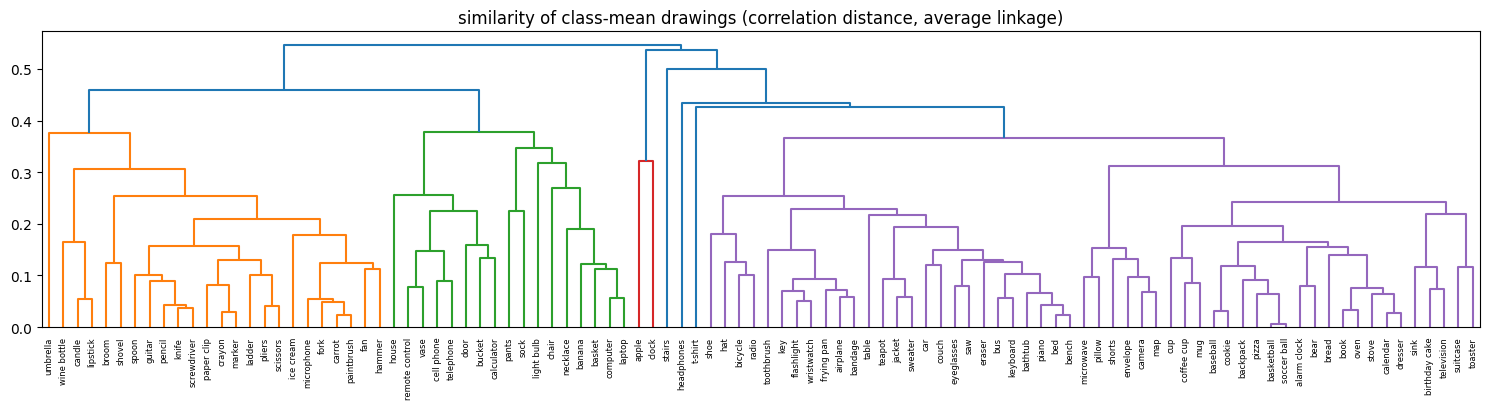

10 most similar class pairs by mean-image correlation: basketball/soccer ball (0.99), carrot/paintbrush (0.98), bed/bench (0.98), calendar/dresser (0.97), crayon/marker (0.97), baseball/cookie (0.97), book/oven (0.97), knife/screwdriver (0.96), calendar/stove (0.96), bed/piano (0.96)
class-level statistics (training images):


,count,mean,std,min,25%,50%,75%,max
cover,100.0,0.228,0.054,0.124,0.192,0.213,0.264,0.360
bbox_area,100.0,455.033,79.742,280.560,399.499,458.320,521.787,585.897
fill,100.0,0.408,0.063,0.195,0.366,0.403,0.453,0.546
edge,100.0,172.996,38.518,93.274,146.647,166.618,199.814,259.171
ink,100.0,133.147,31.983,70.387,110.909,126.338,155.205,213.645
intra_var,100.0,0.082,0.015,0.050,0.071,0.078,0.094,0.116
nn_similarity,100.0,0.915,0.052,0.741,0.893,0.926,0.947,0.994


In [5]:
# ---------- EDA 2: which classes look alike? (hierarchical clustering of class means) + per-class statistics ----------
cm_ = means - means.mean(1, keepdims=True); cosm = (cm_ @ cm_.T) / (np.linalg.norm(cm_, axis=1)[:, None] * np.linalg.norm(cm_, axis=1)[None] + 1e-9); np.fill_diagonal(cosm, -1)
nn_sim = cosm.max(1); nn_cls = cosm.argmax(1); Z = linkage(means, "average", metric="correlation")
fig, ax = plt.subplots(figsize=(15, 4.2)); dendrogram(Z, labels=CLASSES, leaf_font_size=6, ax=ax); plt.title("similarity of class-mean drawings (correlation distance, average linkage)"); plt.xticks(rotation=90); plt.tight_layout(); plt.savefig(f"{OUT_H}/class_dendrogram.png", dpi=110); plt.show()
iu = np.triu_indices(NC, 1); order = np.argsort(cosm[iu])[::-1][:10]; print("10 most similar class pairs by mean-image correlation:", ", ".join(f"{CLASSES[iu[0][i]]}/{CLASSES[iu[1][i]]} ({cosm[iu][i]:.2f})" for i in order))
cls_tab = DF[DF.split == "train"].groupby("cls")[["cover", "bbox_area", "fill", "edge", "ink"]].mean(); cls_tab["intra_var"] = [X[(y == k) & (split == "train")].astype(np.float32).var(0).mean() / 255 ** 2 for k in range(NC)]
cls_tab["nn_similarity"] = nn_sim; cls_tab.index = CLASSES; print("class-level statistics (training images):"); display(cls_tab.describe().T.round(3))


## 3. Metrics, TP/FP/FN/TN for every class

TEST SET (30,000 drawings never used for training or model selection); chance top-1 = 1.0%
  top-1 82.67% [95% CI 82.24%, 83.11%] | top-5 95.41% [95.17%, 95.66%] | macro-F1 0.826 [0.821, 0.830]


,top1,top3,top5,top10,macro_F1,balanced_acc,kappa,MCC,macro_AUC_ovr,NLL,Brier,ECE,mean_confidence,mean_reciprocal_rank
metric,0.8267,0.9348,0.9541,0.971,0.8258,0.827,0.825,0.825,0.9952,0.6693,0.2476,0.0564,0.7704,0.8843



TP / FP / FN / TN per class: 10 hardest classes (lowest F1)


,support,TP,FP,FN,TN,precision,recall_TPR,specificity_TNR,FPR,F1,AUC,top5_recall,mean_conf
marker,315,150,118,165,29567,0.560,0.476,0.996,0.004,0.515,0.974,0.889,0.481
cup,284,140,99,144,29617,0.586,0.493,0.997,0.003,0.535,0.991,0.965,0.565
crayon,266,145,115,121,29619,0.558,0.545,0.996,0.004,0.551,0.989,0.910,0.528
coffee cup,291,160,107,131,29602,0.599,0.550,0.996,0.004,0.573,0.993,0.966,0.558
oven,340,174,71,166,29589,0.710,0.512,0.998,0.002,0.595,0.982,0.888,0.589
mug,321,229,171,92,29508,0.572,0.713,0.994,0.006,0.635,0.992,0.966,0.542
bench,303,188,99,115,29598,0.655,0.620,0.997,0.003,0.637,0.991,0.941,0.649
pliers,310,208,125,102,29565,0.625,0.671,0.996,0.004,0.647,0.984,0.916,0.688
keyboard,301,201,111,100,29588,0.644,0.668,0.996,0.004,0.656,0.992,0.940,0.616
eraser,317,217,105,100,29578,0.674,0.685,0.996,0.004,0.679,0.984,0.886,0.669


10 easiest classes


,support,TP,FP,FN,TN,precision,recall_TPR,specificity_TNR,FPR,F1,AUC,top5_recall,mean_conf
bus,306,283,15,23,29679,0.950,0.925,0.999,0.001,0.937,0.998,0.961,0.843
house,287,272,21,15,29692,0.928,0.948,0.999,0.001,0.938,0.997,0.979,0.870
ice cream,301,282,18,19,29681,0.940,0.937,0.999,0.001,0.938,0.998,0.983,0.868
stairs,309,285,9,24,29682,0.969,0.922,1.000,0.000,0.945,0.997,0.958,0.878
bicycle,269,260,21,9,29710,0.925,0.967,0.999,0.001,0.945,1.000,0.993,0.880
umbrella,273,262,17,11,29710,0.939,0.960,0.999,0.001,0.949,0.999,0.978,0.893
apple,304,292,17,12,29679,0.945,0.961,0.999,0.001,0.953,1.000,0.984,0.893
headphones,274,259,9,15,29717,0.966,0.945,1.000,0.000,0.956,0.998,0.971,0.881
envelope,292,277,9,15,29699,0.969,0.949,1.000,0.000,0.958,0.996,0.962,0.896
ladder,346,335,17,11,29637,0.952,0.968,0.999,0.001,0.960,0.999,0.983,0.914


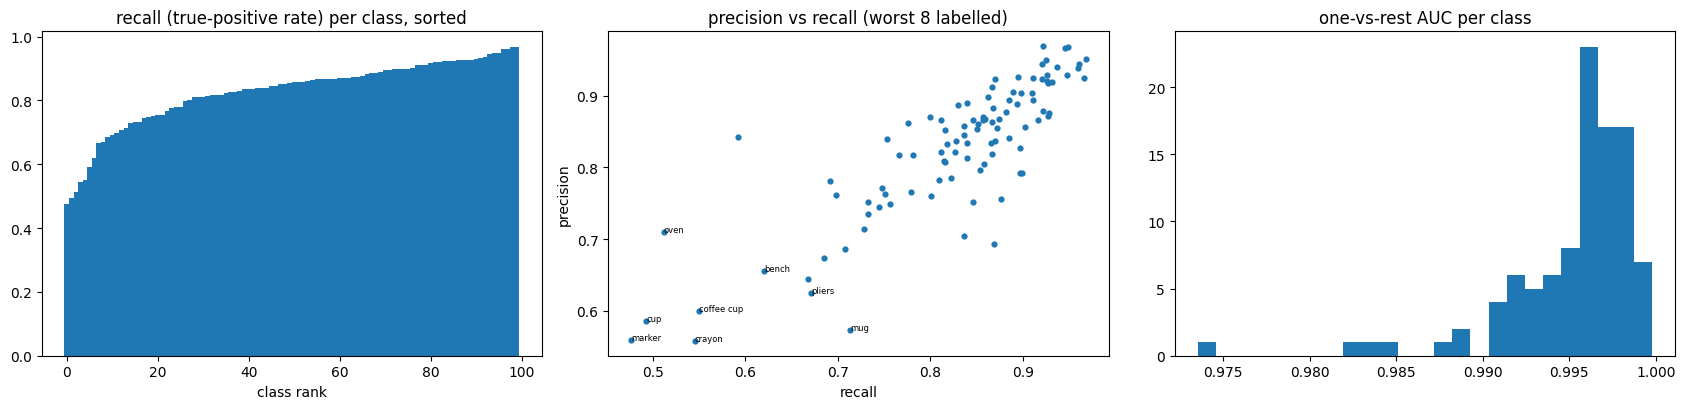

In [6]:
# ---------- metrics on the held-out test set ----------
def cm_np(yy, pp, n=NC): return np.bincount(np.asarray(yy) * n + np.asarray(pp), minlength=n * n).reshape(n, n)
def macro_f1_cm(cm):
    tp = np.diag(cm); d = 2 * tp + cm.sum(0) - tp + cm.sum(1) - tp; return float(np.mean(np.where(d > 0, 2 * tp / np.maximum(d, 1), 0)))
def ece(P, yy, bins=15):
    conf, ok = P.max(1), P.argmax(1) == yy; b = np.linspace(0, 1, bins + 1); e = 0.
    for lo, hi in zip(b[:-1], b[1:]):
        m = (conf > lo) & (conf <= hi); e += m.mean() * abs(ok[m].mean() - conf[m].mean()) if m.any() else 0
    return e
rank = (Pte > Pte[np.arange(len(yte)), yte][:, None]).sum(1); cm = cm_np(yte, pred)
rng = np.random.default_rng(SEED); idx = rng.integers(0, len(yte), (BOOT, len(yte))); bs = np.array([[np.mean(pred[i] == yte[i]), np.mean(rank[i] < 5), macro_f1_cm(cm_np(yte[i], pred[i]))] for i in idx])
ci = np.percentile(bs, [2.5, 97.5], 0); aucs = roc_auc_score(yte, Pte / Pte.sum(1, keepdims=True), multi_class="ovr", average=None, labels=list(range(NC)))
M = dict(top1=np.mean(rank < 1), top3=np.mean(rank < 3), top5=np.mean(rank < 5), top10=np.mean(rank < 10), macro_F1=macro_f1_cm(cm), balanced_acc=balanced_accuracy_score(yte, pred), kappa=cohen_kappa_score(yte, pred), MCC=matthews_corrcoef(yte, pred),
         macro_AUC_ovr=float(np.mean(aucs)), NLL=float(-np.log(Pte[np.arange(len(yte)), yte] + 1e-12).mean()), Brier=float(((Pte - np.eye(NC)[yte]) ** 2).sum(1).mean()), ECE=ece(Pte, yte), mean_confidence=float(Pte.max(1).mean()), mean_reciprocal_rank=float(np.mean(1 / (rank + 1))))
print(f"TEST SET ({len(yte):,} drawings never used for training or model selection); chance top-1 = {1 / NC:.1%}")
print(f"  top-1 {M['top1']:.2%} [95% CI {ci[0, 0]:.2%}, {ci[1, 0]:.2%}] | top-5 {M['top5']:.2%} [{ci[0, 1]:.2%}, {ci[1, 1]:.2%}] | macro-F1 {M['macro_F1']:.3f} [{ci[0, 2]:.3f}, {ci[1, 2]:.3f}]")
display(pd.Series({k: round(float(v), 4) for k, v in M.items()}, name="metric").to_frame().T); json.dump({k: float(v) for k, v in M.items()}, open(f"{OUT_H}/metrics_{MID}.json", "w"), indent=1)
tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; tn = cm.sum() - tp - fp - fn
PC = pd.DataFrame(dict(support=cm.sum(1), TP=tp, FP=fp, FN=fn, TN=tn, precision=tp / np.maximum(tp + fp, 1), recall_TPR=tp / np.maximum(tp + fn, 1), specificity_TNR=tn / np.maximum(tn + fp, 1), FPR=fp / np.maximum(fp + tn, 1),
                       F1=2 * tp / np.maximum(2 * tp + fp + fn, 1), AUC=aucs, top5_recall=[np.mean(rank[yte == k] < 5) for k in range(NC)], mean_conf=[Pte[yte == k].max(1).mean() for k in range(NC)]), index=CLASSES)
PC.to_csv(f"{OUT_H}/per_class_metrics_{MID}.csv"); print("\nTP / FP / FN / TN per class: 10 hardest classes (lowest F1)"); display(PC.sort_values("F1").head(10).round(3)); print("10 easiest classes"); display(PC.sort_values("F1").tail(10).round(3))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2)); o = PC.sort_values("recall_TPR"); ax[0].bar(range(NC), o.recall_TPR, width=1.); ax[0].set_title("recall (true-positive rate) per class, sorted"); ax[0].set_xlabel("class rank")
ax[1].scatter(PC.recall_TPR, PC.precision, s=12); [ax[1].annotate(n, (r.recall_TPR, r.precision), fontsize=6) for n, r in PC.sort_values("F1").head(8).iterrows()]; ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("precision vs recall (worst 8 labelled)")
ax[2].hist(PC.AUC, 25); ax[2].set_title("one-vs-rest AUC per class"); plt.tight_layout(); plt.savefig(f"{OUT_H}/per_class_metrics.png", dpi=110); plt.show()


## 4. Confusions

25 most frequent confusions (true -> predicted); asymmetry = n / reverse_n (large = a one-way confusion, e.g. a class that 'absorbs' another):


,true,predicted_as,n,share_of_true_class,reverse_n,asymmetry
0,coffee cup,mug,86,0.296,42,2.048
1,cup,mug,71,0.250,28,2.536
2,telephone,cell phone,71,0.237,2,35.500
3,computer,laptop,66,0.210,15,4.400
4,sweater,t-shirt,47,0.145,23,2.043
5,jacket,sweater,46,0.147,27,1.704
6,mug,coffee cup,42,0.131,86,0.488
7,cup,coffee cup,41,0.144,25,1.640
8,oven,stove,40,0.118,14,2.857
9,pants,shorts,38,0.125,32,1.188


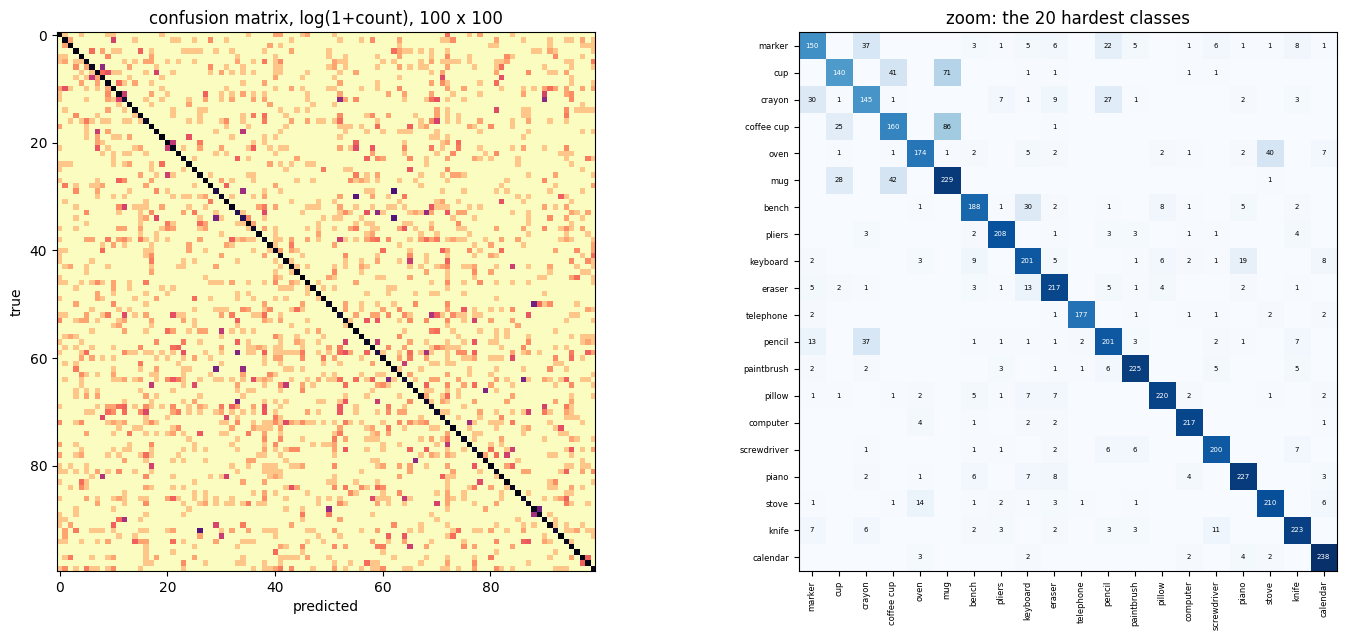

In [7]:
# ---------- confusion analysis ----------
off = cm.copy(); np.fill_diagonal(off, 0); top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:25], off.shape))[0]
rows = [dict(true=CLASSES[a], predicted_as=CLASSES[b], n=int(off[a, b]), share_of_true_class=off[a, b] / cm[a].sum(), reverse_n=int(off[b, a]), asymmetry=off[a, b] / max(off[b, a], 1)) for a, b in top]
CONF = pd.DataFrame(rows); print("25 most frequent confusions (true -> predicted); asymmetry = n / reverse_n (large = a one-way confusion, e.g. a class that 'absorbs' another):"); display(CONF.round(3)); CONF.to_csv(f"{OUT_H}/top_confusions_{MID}.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5)); ax[0].imshow(np.log1p(cm), cmap="magma_r"); ax[0].set_title("confusion matrix, log(1+count), 100 x 100"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
w20 = PC.sort_values("F1").head(20).index; wi = [CLASSES.index(c) for c in w20]; sub = cm[np.ix_(wi, wi)]; ax[1].imshow(sub, cmap="Blues")
for i in range(20):
    for j in range(20):
        if sub[i, j]: ax[1].text(j, i, sub[i, j], ha="center", va="center", fontsize=5, color="white" if sub[i, j] > sub.max() / 2 else "black")
ax[1].set_xticks(range(20)); ax[1].set_yticks(range(20)); ax[1].set_xticklabels(w20, rotation=90, fontsize=6); ax[1].set_yticklabels(w20, fontsize=6); ax[1].set_title("zoom: the 20 hardest classes")
plt.tight_layout(); plt.savefig(f"{OUT_H}/confusion_matrix.png", dpi=110); plt.show()


## 5. ROC / PR / top-k / calibration / selective prediction

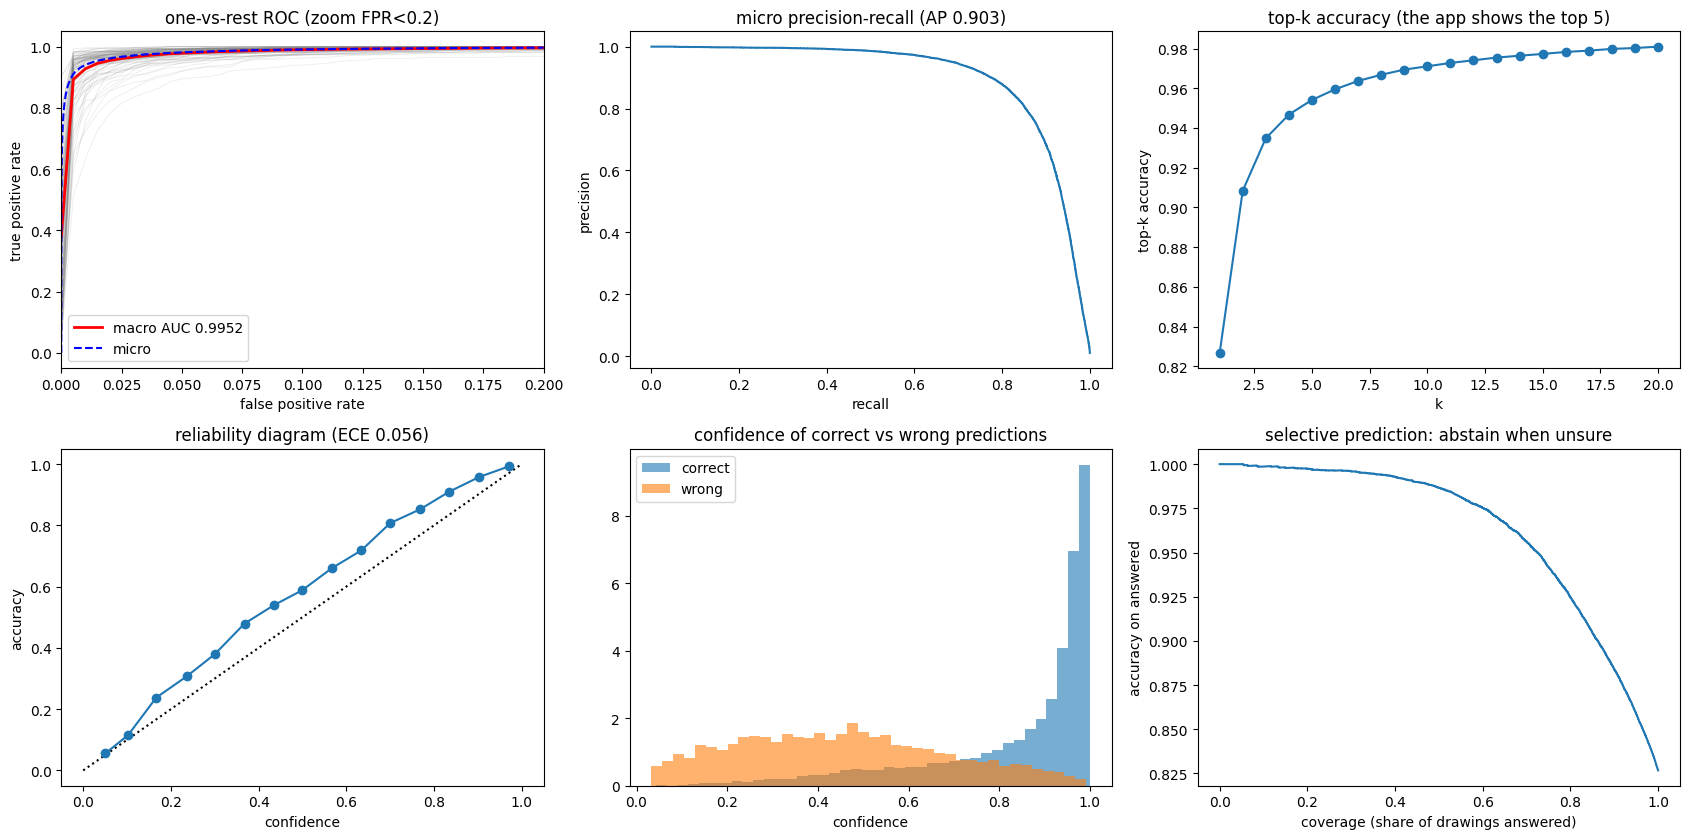

  to reach 90% accuracy the model must answer only 86.2% of drawings
  to reach 95% accuracy the model must answer only 72.5% of drawings
  to reach 98% accuracy the model must answer only 56.0% of drawings

temperature scaling (fitted on the validation split only): T = 0.82 | test NLL 0.669 -> 0.640 | test ECE 0.056 -> 0.006 | accuracy unchanged (82.67%)
(the model was trained with label smoothing 0.05, so under-confidence is expected: T < 1 sharpens)


In [8]:
# ---------- ROC / PR / top-k / calibration / temperature scaling / selective prediction ----------
Y1 = np.eye(NC)[yte]; fpr_grid = np.linspace(0, 1, 200); tprs = []
for k in range(NC): f_, t_, _ = roc_curve(Y1[:, k], Pte[:, k]); tprs.append(np.interp(fpr_grid, f_, t_))
fig, ax = plt.subplots(2, 3, figsize=(17, 8.5)); [ax[0, 0].plot(fpr_grid, t, c="gray", alpha=.15, lw=.6) for t in tprs]; ax[0, 0].plot(fpr_grid, np.mean(tprs, 0), "r", lw=2, label=f"macro AUC {np.mean(aucs):.4f}")
f_, t_, _ = roc_curve(Y1.ravel(), Pte.ravel()); ax[0, 0].plot(f_, t_, "b--", label="micro"); ax[0, 0].set_xlim(0, .2); ax[0, 0].set_xlabel("false positive rate"); ax[0, 0].set_ylabel("true positive rate"); ax[0, 0].set_title("one-vs-rest ROC (zoom FPR<0.2)"); ax[0, 0].legend()
p_, r_, _ = precision_recall_curve(Y1.ravel(), Pte.ravel()); ax[0, 1].plot(r_, p_); ax[0, 1].set_title(f"micro precision-recall (AP {average_precision_score(Y1.ravel(), Pte.ravel()):.3f})"); ax[0, 1].set_xlabel("recall"); ax[0, 1].set_ylabel("precision")
ks = np.arange(1, 21); ax[0, 2].plot(ks, [np.mean(rank < k) for k in ks], "o-"); ax[0, 2].set_xlabel("k"); ax[0, 2].set_ylabel("top-k accuracy"); ax[0, 2].set_title("top-k accuracy (the app shows the top 5)")
conf, ok = Pte.max(1), pred == yte; b = np.linspace(0, 1, 16); bx, by, bn = [], [], []
for lo, hi in zip(b[:-1], b[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.sum() >= 5: bx.append(conf[m].mean()); by.append(ok[m].mean()); bn.append(m.sum())
ax[1, 0].plot([0, 1], [0, 1], "k:"); ax[1, 0].plot(bx, by, "o-"); ax[1, 0].set_xlabel("confidence"); ax[1, 0].set_ylabel("accuracy"); ax[1, 0].set_title(f"reliability diagram (ECE {M['ECE']:.3f})")
ax[1, 1].hist(conf[ok], 40, alpha=.6, label="correct", density=True); ax[1, 1].hist(conf[~ok], 40, alpha=.6, label="wrong", density=True); ax[1, 1].legend(); ax[1, 1].set_title("confidence of correct vs wrong predictions"); ax[1, 1].set_xlabel("confidence")
o = np.argsort(-conf); cov = np.arange(1, len(o) + 1) / len(o); accs = np.cumsum(ok[o]) / np.arange(1, len(o) + 1); ax[1, 2].plot(cov, accs); ax[1, 2].set_xlabel("coverage (share of drawings answered)"); ax[1, 2].set_ylabel("accuracy on answered"); ax[1, 2].set_title("selective prediction: abstain when unsure")
plt.tight_layout(); plt.savefig(f"{OUT_H}/curves_calibration.png", dpi=110); plt.show()
for tgt in (.90, .95, .98): c_ = cov[np.where(accs >= tgt)[0]]; print(f"  to reach {tgt:.0%} accuracy the model must answer only {c_.max():.1%} of drawings" if len(c_) else f"  {tgt:.0%} accuracy is never reached")
nll = lambda lt, L, yy: float(-np.log(softmax(L / np.exp(lt))[np.arange(len(yy)), yy] + 1e-12).mean()); T = float(np.exp(minimize_scalar(lambda lt: nll(lt, LG["va"], yva), bounds=(-2, 2), method="bounded").x)); Pt = softmax(LG["te"] / T)
print(f"\ntemperature scaling (fitted on the validation split only): T = {T:.2f} | test NLL {M['NLL']:.3f} -> {nll(np.log(T), LG['te'], yte):.3f} | test ECE {M['ECE']:.3f} -> {ece(Pt, yte):.3f} | accuracy unchanged ({np.mean(Pt.argmax(1) == yte):.2%})")
print("(the model was trained with label smoothing 0.05, so under-confidence is expected: T < 1 sharpens)")


## 6. Regression: what makes a class or a drawing hard

linear regression of per-class recall on class properties (standardised; R2 = 0.31, 100 classes). std_coef = change in recall per +1 SD of the property:


,std_coef,CI_lo,CI_hi,spearman_with_recall,spearman_p
cover,0.176,0.034,0.334,-0.103,0.307
bbox_area,-0.021,-0.120,0.086,0.087,0.388
fill,-0.054,-0.143,0.032,-0.299,0.002
edge,-0.013,-0.096,0.047,-0.037,0.715
intra_var,-0.132,-0.200,-0.068,-0.218,0.029
nn_similarity,-0.025,-0.044,-0.004,-0.437,0.000


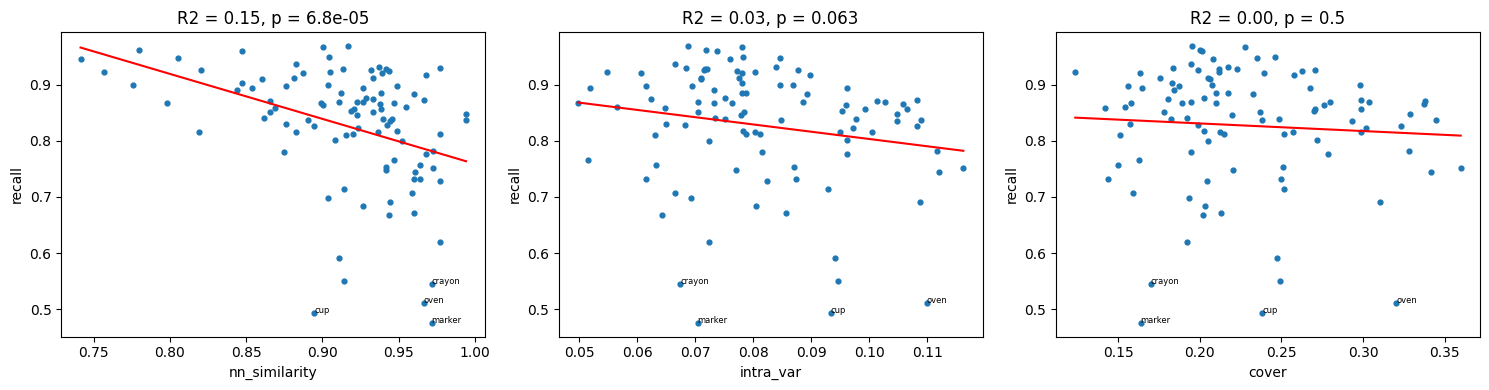

logistic regression: is a test drawing recognised correctly? odds ratio per +1 SD of the property (>1 = easier):


,odds_ratio_per_SD,OR_lo,OR_hi
cover,0.461,0.383,0.542
bbox_area,0.925,0.753,1.075
fill,1.031,0.888,1.179
abs_off,1.018,0.960,1.072
edge,2.309,2.029,2.624


accuracy by decile of ink coverage: ['0.80', '0.83', '0.85', '0.86', '0.85', '0.84', '0.83', '0.81', '0.79', '0.79']
accuracy by decile of bounding-box area: ['0.81', '0.83', '0.83', '0.83', '0.83', '0.83', '0.87', '0.83', '0.83', '0.84']


In [9]:
# ---------- regression I: why are some classes hard? (class recall ~ class properties) ----------
cd = cls_tab.copy(); cd["recall"] = PC.recall_TPR.values; cd["precision"] = PC.precision.values; feats = ["cover", "bbox_area", "fill", "edge", "intra_var", "nn_similarity"]
Zc = (cd[feats] - cd[feats].mean()) / cd[feats].std(); lm = LinearRegression().fit(Zc, cd.recall); coef = lm.coef_; r2 = lm.score(Zc, cd.recall); rr = np.random.default_rng(SEED)
bsc = np.array([LinearRegression().fit(Zc.iloc[i], cd.recall.iloc[i]).coef_ for i in (rr.integers(0, NC, NC) for _ in range(500))])
R1 = pd.DataFrame(dict(std_coef=coef, CI_lo=np.percentile(bsc, 2.5, 0), CI_hi=np.percentile(bsc, 97.5, 0), spearman_with_recall=[stats.spearmanr(cd[f_], cd.recall).correlation for f_ in feats], spearman_p=[stats.spearmanr(cd[f_], cd.recall).pvalue for f_ in feats]), index=feats)
print(f"linear regression of per-class recall on class properties (standardised; R2 = {r2:.2f}, {NC} classes). std_coef = change in recall per +1 SD of the property:"); display(R1.round(3)); R1.to_csv(f"{OUT_H}/regression_class_recall_{MID}.csv")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, f_ in zip(ax, ["nn_similarity", "intra_var", "cover"]):
    a_.scatter(cd[f_], cd.recall, s=12); lg = stats.linregress(cd[f_], cd.recall); xx = np.linspace(cd[f_].min(), cd[f_].max(), 20); a_.plot(xx, lg.intercept + lg.slope * xx, "r"); a_.set_xlabel(f_); a_.set_ylabel("recall"); a_.set_title(f"R2 = {lg.rvalue ** 2:.2f}, p = {lg.pvalue:.2g}")
    for n, r in cd.sort_values("recall").head(4).iterrows(): a_.annotate(n, (r[f_], r.recall), fontsize=6)
plt.tight_layout(); plt.savefig(f"{OUT_H}/regression_class_level.png", dpi=110); plt.show()
# ---------- regression II: which drawings are recognised? (logistic regression on the test images) ----------
ft = DF.iloc[te].reset_index(drop=True); cols = ["cover", "bbox_area", "fill", "off_x", "off_y", "edge"]; ft["abs_off"] = np.hypot(ft.off_x, ft.off_y); cols = ["cover", "bbox_area", "fill", "abs_off", "edge"]   # rows in the same order as te / pred / ok
Zi = ((ft[cols] - ft[cols].mean()) / ft[cols].std()).values; yc = ok.astype(int)
if (1 - yc).sum() < 30 or yc.sum() < 30: print(f"only {int((1 - yc).sum())} errors among {len(yc)} test drawings: too few for a logistic regression on drawing properties")
else:
    lr = LogisticRegression(C=1e6, max_iter=3000).fit(Zi, yc); bo = np.array([LogisticRegression(C=1e6, max_iter=3000).fit(Zi[i], yc[i]).coef_[0] for i in (rr.integers(0, len(yc), min(len(yc), 10000)) for _ in range(60))])
    R2 = pd.DataFrame(dict(odds_ratio_per_SD=np.exp(lr.coef_[0]), OR_lo=np.exp(np.percentile(bo, 2.5, 0)), OR_hi=np.exp(np.percentile(bo, 97.5, 0))), index=cols)
    print("logistic regression: is a test drawing recognised correctly? odds ratio per +1 SD of the property (>1 = easier):"); display(R2.round(3)); R2.to_csv(f"{OUT_H}/regression_image_correct_{MID}.csv")
q = pd.qcut(ft.cover, 10, duplicates="drop"); acc_q = pd.Series(ok).groupby(q.values).mean(); print("accuracy by decile of ink coverage:", [f"{v:.2f}" for v in acc_q.values]); print("accuracy by decile of bounding-box area:", [f"{v:.2f}" for v in pd.Series(ok).groupby(pd.qcut(ft.bbox_area, 10, duplicates="drop").values).mean().values])


## 7. Robustness without retraining

robustness sweep: loaded analysis_H_quickdraw/robust_d10a83e0.json (not recomputed)


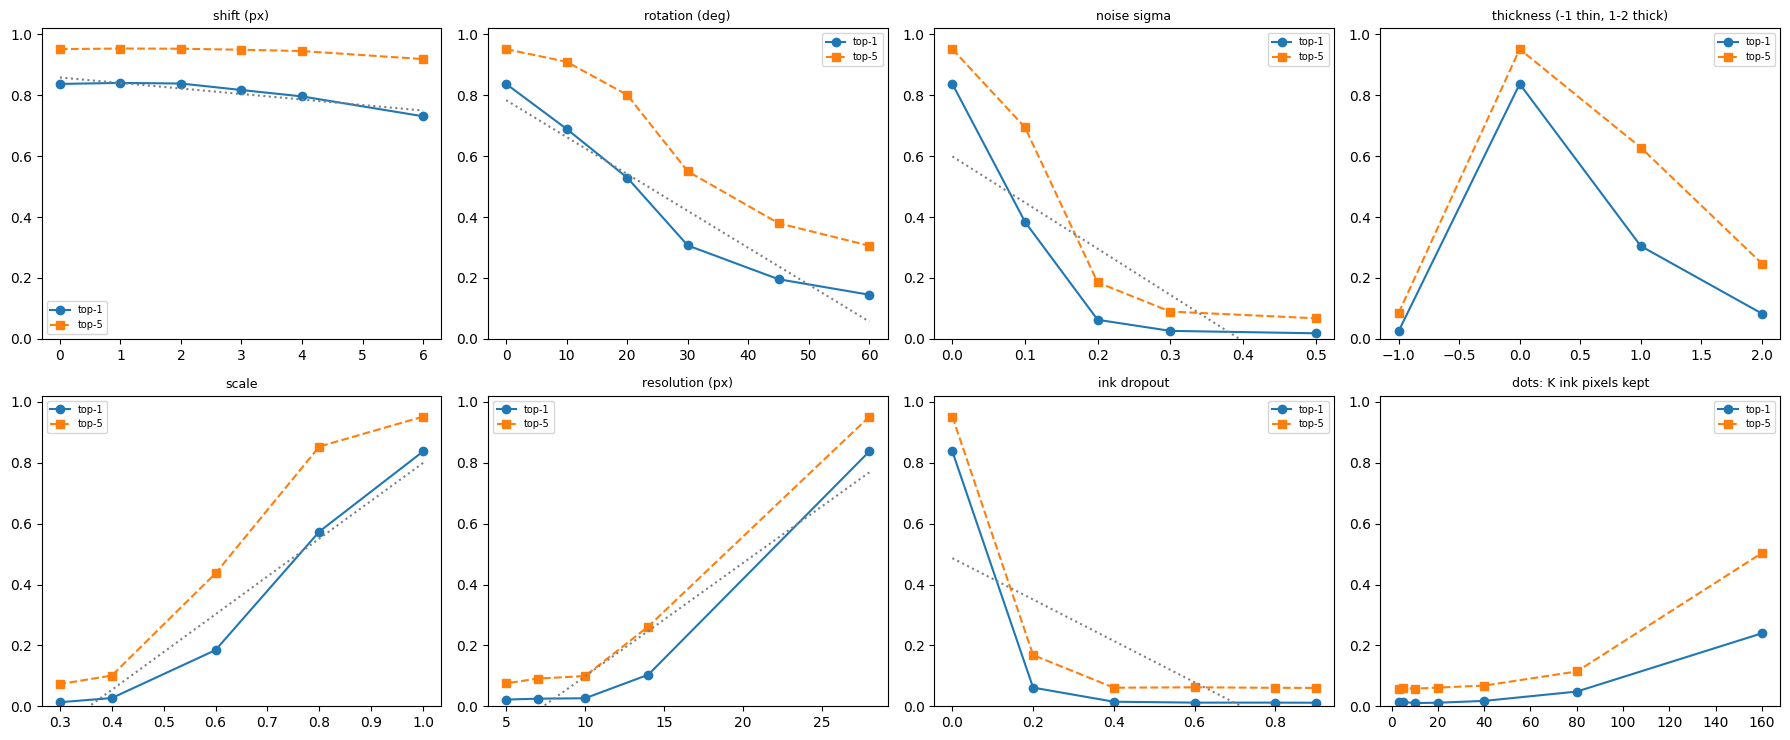

linear regression of top-1 accuracy on perturbation strength (3,000 test drawings per setting):


,perturbation,slope_top1_per_unit,R2,p,top1_clean,top1_worst
0,shift (px),-0.0181,0.8498,0.0089,0.8373,0.7310
1,rotation (deg),-0.0121,0.9332,0.0017,0.8373,0.1447
2,noise sigma,-1.5164,0.6793,0.0861,0.8373,0.0180
3,scale,1.2427,0.9556,0.0040,0.8373,0.0133
4,resolution (px),0.0372,0.9132,0.0111,0.8373,0.0220
5,ink dropout,-0.6794,0.5056,0.1132,0.8373,0.0117


thickness (top-1): {-1: 0.025, 0: 0.837, 1: 0.305, 2: 0.083}


In [10]:
# ---------- robustness WITHOUT retraining: how does Module A degrade? (regression of accuracy on perturbation strength; includes the sparse-dot test relevant to the prosthetic pipeline) ----------
GUESS = 1 / NC; gk = torch.exp(-(torch.arange(-1, 2).float()[:, None] ** 2 + torch.arange(-1, 2).float()[None] ** 2) / (2 * .5 ** 2))[None, None]      # 3x3 blob with sigma 0.5 px: marks the dot without thickening the stroke
def pert(x, kind, lv, g):
    if kind == "shift": return torch.roll(x, int(lv), 3)
    if kind == "rotate":
        th = math.radians(lv); A = torch.tensor([[math.cos(th), -math.sin(th), 0], [math.sin(th), math.cos(th), 0]], dtype=x.dtype, device=x.device)[None].expand(len(x), -1, -1)
        return F.grid_sample(x, F.affine_grid(A, list(x.shape), align_corners=False), align_corners=False)
    if kind == "noise": return (x + lv * torch.randn(x.shape, generator=g).to(x.device)).clamp(0, 1)
    if kind == "thick": return -F.max_pool2d(-x, 3, 1, 1) if lv < 0 else (x if lv == 0 else F.max_pool2d(x, 2 * int(lv) + 1, 1, int(lv)))
    if kind == "scale": s = max(int(round(28 * lv)), 4); sm = F.interpolate(x, size=(s, s), mode="bilinear", align_corners=False); p = 28 - s; return F.pad(sm, (p // 2, p - p // 2, p // 2, p - p // 2))
    if kind == "lowres": return F.interpolate(F.adaptive_avg_pool2d(x, int(lv)), size=28, mode="nearest")
    if kind == "drop": return x * (torch.rand(x.shape, generator=g).to(x.device) > lv).float()
    on = (x > .2).float().flatten(1); sc = torch.rand(on.shape, generator=g).to(x.device) * on; m = torch.zeros_like(on).scatter_(1, sc.topk(int(lv), 1).indices, 1.) * on   # 'dots': keep only K ink pixels, draw each as a small blob
    return F.conv2d(m.view_as(x), gk.to(x.device), padding=1).clamp(0, 1)
SWEEP = {"shift (px)": ("shift", [0, 1, 2, 3, 4, 6]), "rotation (deg)": ("rotate", [0, 10, 20, 30, 45, 60]), "noise sigma": ("noise", [0, .1, .2, .3, .5]), "thickness (-1 thin, 1-2 thick)": ("thick", [-1, 0, 1, 2]),
         "scale": ("scale", [1., .8, .6, .4, .3]), "resolution (px)": ("lowres", [28, 14, 10, 7, 5]), "ink dropout": ("drop", [0, .2, .4, .6, .8, .9]), "dots: K ink pixels kept": ("dots", [3, 5, 10, 20, 40, 80, 160])}
def robust_build():
    sel = np.random.default_rng(SEED).choice(len(te), min(N_ROB, len(te)), replace=False); xs = torch.from_numpy(X[te][sel]).to(dev).float().div(255).view(-1, 1, 28, 28); ys = torch.from_numpy(yte[sel]).to(dev); res = {}
    for name, (kind, lvls) in SWEEP.items():
        for lv in lvls:
            g = torch.Generator().manual_seed(SEED); c1 = c5 = 0
            with torch.no_grad():
                for i in range(0, len(xs), 1000):
                    lg_ = net(pert(xs[i:i + 1000], kind, lv, g)); t5 = lg_.topk(5, 1).indices; c1 += (t5[:, 0] == ys[i:i + 1000]).sum().item(); c5 += (t5 == ys[i:i + 1000, None]).any(1).sum().item()
            res[f"{name}|{lv}"] = [c1 / len(xs), c5 / len(xs)]
    res["_n"] = len(xs); return res
def robust_cached():
    f = f"{OUT_H}/robust_{MID}.json"
    if os.path.exists(f): print("robustness sweep: loaded", f, "(not recomputed)"); return json.load(open(f))
    t0 = time.time(); r = robust_build(); json.dump(r, open(f, "w")); print(f"robustness sweep computed in {time.time() - t0:.0f}s"); return r
RB = once("RB", KEY, robust_cached); nR = RB["_n"]; fig, ax = plt.subplots(2, 4, figsize=(18, 7.5)); rows = []
for a_, (name, (kind, lvls)) in zip(ax.ravel(), SWEEP.items()):
    t1 = [RB[f"{name}|{l}"][0] for l in lvls]; t5 = [RB[f"{name}|{l}"][1] for l in lvls]; a_.plot(lvls, t1, "o-", label="top-1"); a_.plot(lvls, t5, "s--", label="top-5"); a_.set_title(name, fontsize=9); a_.set_ylim(0, 1.02); a_.legend(fontsize=7)
    if kind != "thick" and kind != "dots": lg = stats.linregress(lvls, t1); a_.plot(lvls, lg.intercept + lg.slope * np.array(lvls), ":", c="gray"); rows.append(dict(perturbation=name, slope_top1_per_unit=lg.slope, R2=lg.rvalue ** 2, p=lg.pvalue, top1_clean=t1[0] if kind != "scale" else t1[0], top1_worst=t1[-1]))
plt.tight_layout(); plt.savefig(f"{OUT_H}/robustness.png", dpi=110); plt.show(); print(f"linear regression of top-1 accuracy on perturbation strength ({nR:,} test drawings per setting):"); display(pd.DataFrame(rows).round(4))
print("thickness (top-1):", {l: round(RB[f'thickness (-1 thin, 1-2 thick)|{l}'][0], 3) for l in SWEEP["thickness (-1 thin, 1-2 thick)"][1]})


## 8. Sparse dots: how many does a 100-class identifier need?

psychometric fit (100 classes, chance 1%): K for 50% top-1 = 243.1 [228.2, 257.2] | K for 90% = 531.0 [459.7, 601.2] (extrapolated if above 160)


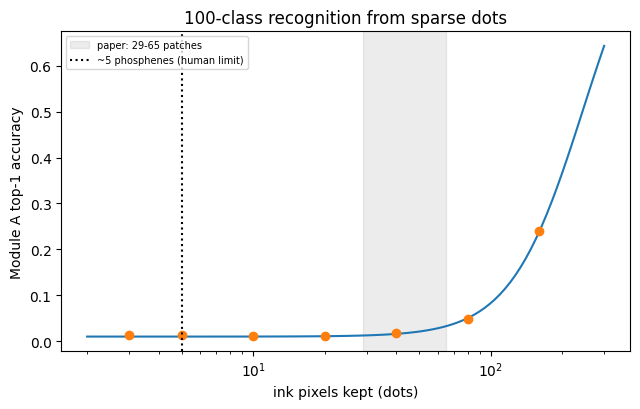

Reading: this is a 100-class problem on 28x28 drawings that the model was trained on with FULL strokes; dots are an out-of-distribution input. Accuracy would rise if Module A were fine-tuned on dot renderings.


In [11]:
# ---------- how many dots does a 100-class identifier need? psychometric fit of top-1 accuracy versus K kept ink pixels (compare with Module G's K for the phosphene evaluator) ----------
Kd = np.array(SWEEP["dots: K ink pixels kept"][1], float); acc = np.array([RB[f"dots: K ink pixels kept|{int(k)}"][0] for k in Kd]); nc_ = np.round(acc * nR)
def psy(x, m, b): return GUESS + (1 - GUESS) / (1 + np.exp(-b * (x - m)))
def fit_psy(xs, nc, nt):
    def nll_(p): pr = np.clip(psy(xs, p[0], np.clip(p[1], .05, 20)), 1e-6, 1 - 1e-6); return -(nc * np.log(pr) + (nt - nc) * np.log(1 - pr)).sum()
    b = min((minimize(nll_, [m0, 1.], method="Nelder-Mead") for m0 in (xs.min(), np.median(xs), xs.max())), key=lambda r: r.fun); return b.x[0], float(np.clip(b.x[1], .05, 20))
def k_at(m, b, p): s = (p - GUESS) / (1 - GUESS); return float(2 ** (m + np.log(s / (1 - s)) / b)) if 0 < s < 1 else np.nan
fmtK = lambda v: "n/a" if not np.isfinite(v) else (">10000" if v >= 1e4 else f"{v:.1f}")
m_, b_ = fit_psy(np.log2(Kd), nc_, np.full(len(Kd), nR)); rr = np.random.default_rng(SEED); bs = []
for _ in range(200): ncb = rr.binomial(nR, acc); mb, bb = fit_psy(np.log2(Kd), ncb, np.full(len(Kd), nR)); bs.append([k_at(mb, bb, .5), k_at(mb, bb, .9)])
bs = np.array(bs); print(f"psychometric fit (100 classes, chance {GUESS:.0%}): K for 50% top-1 = {fmtK(k_at(m_, b_, .5))} [{fmtK(np.nanpercentile(bs[:, 0], 2.5))}, {fmtK(np.nanpercentile(bs[:, 0], 97.5))}] | K for 90% = {fmtK(k_at(m_, b_, .9))} [{fmtK(np.nanpercentile(bs[:, 1], 2.5))}, {fmtK(np.nanpercentile(bs[:, 1], 97.5))}] (extrapolated if above {int(Kd.max())})")
xs_ = np.linspace(np.log2(2), np.log2(300), 100); plt.figure(figsize=(6.5, 4.2)); plt.plot(2 ** xs_, psy(xs_, m_, b_), "-"); plt.plot(Kd, acc, "o"); plt.axvspan(29, 65, color="gray", alpha=.15, label="paper: 29-65 patches"); plt.axvline(5, ls=":", c="k", label="~5 phosphenes (human limit)")
plt.xscale("log"); plt.xlabel("ink pixels kept (dots)"); plt.ylabel("Module A top-1 accuracy"); plt.legend(fontsize=7); plt.title("100-class recognition from sparse dots"); plt.tight_layout(); plt.savefig(f"{OUT_H}/dots_psychometric.png", dpi=120); plt.show()
print("Reading: this is a 100-class problem on 28x28 drawings that the model was trained on with FULL strokes; dots are an out-of-distribution input. Accuracy would rise if Module A were fine-tuned on dot renderings.")


## 9. Failures and summary

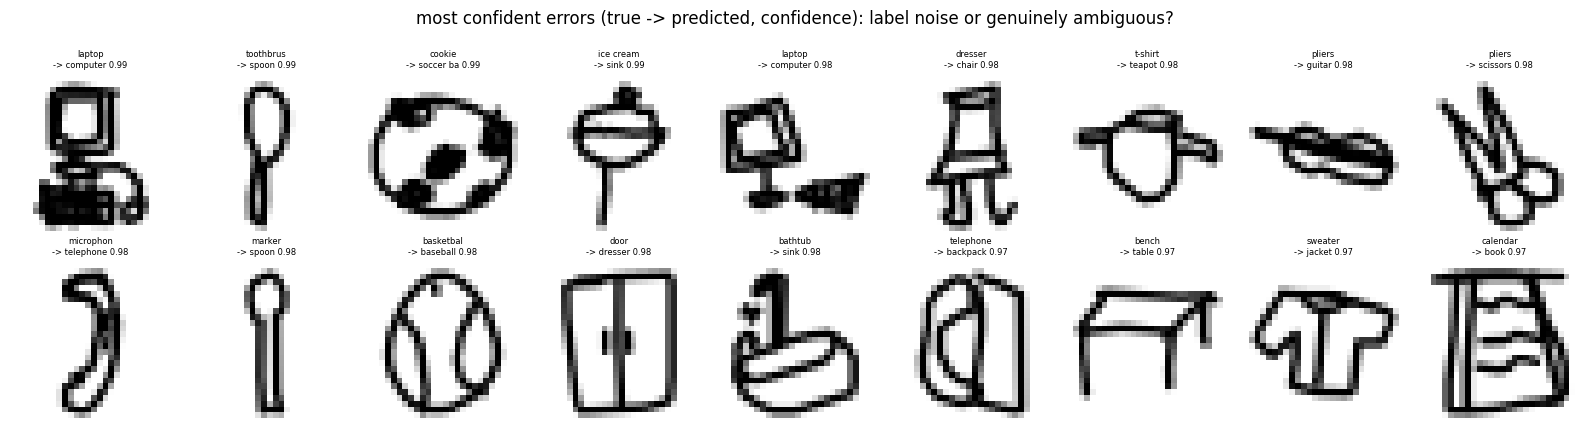

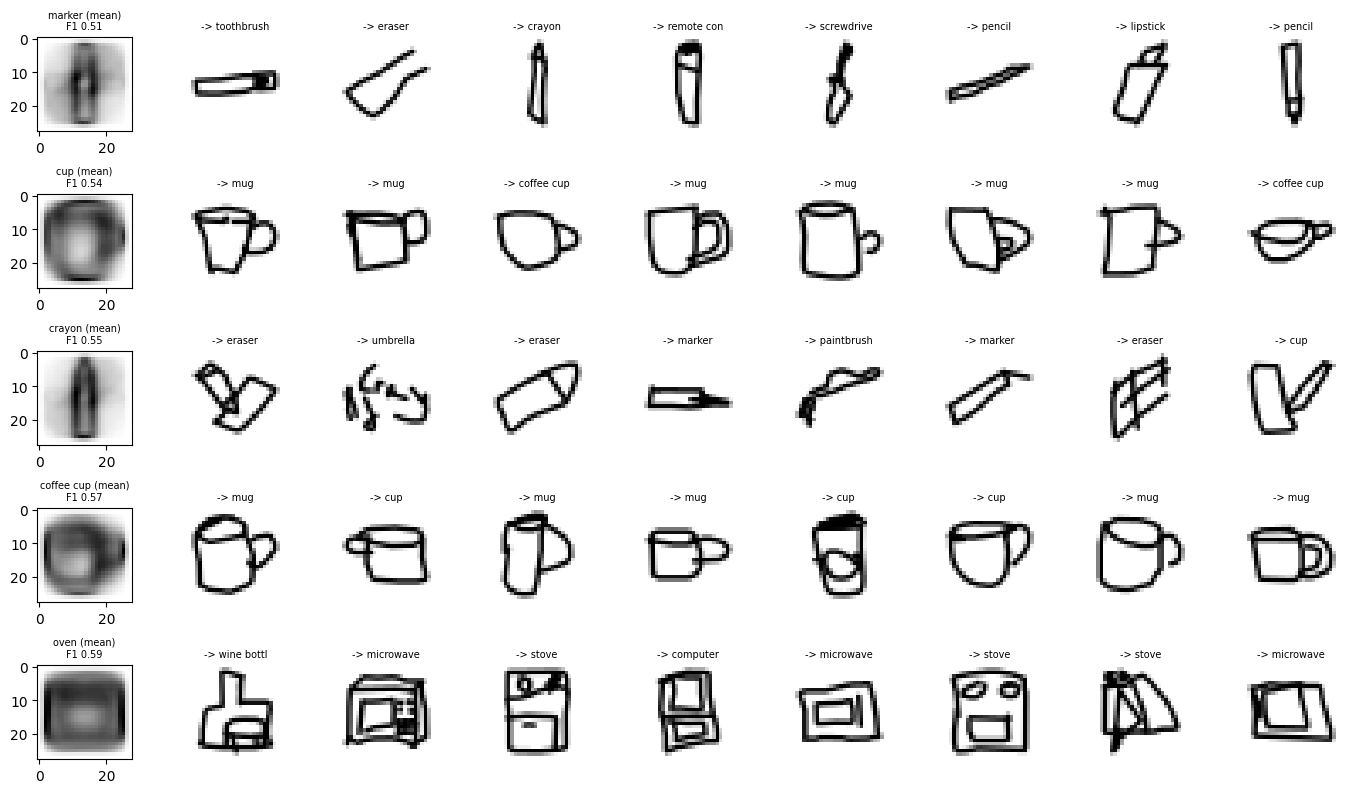

{
 "model_id": "d10a83e0",
 "n_test": 30000,
 "metrics": {
  "top1": 0.8267333333333333,
  "top3": 0.9348,
  "top5": 0.9541,
  "top10": 0.9710333333333333,
  "macro_F1": 0.8258262292559705,
  "balanced_acc": 0.8269830259934191,
  "kappa": 0.8249791514859968,
  "MCC": 0.825005665469287,
  "macro_AUC_ovr": 0.9952197209539387,
  "NLL": 0.6693053245544434,
  "Brier": 0.24761592154126863,
  "ECE": 0.0563553729303181,
  "mean_confidence": 0.7703779935836792,
  "mean_reciprocal_rank": 0.8843287869599471
 },
 "hardest": [
  "marker",
  "cup",
  "crayon",
  "coffee cup",
  "oven"
 ],
 "easiest": [
  "umbrella",
  "apple",
  "headphones",
  "envelope",
  "ladder"
 ],
 "temperature": 0.8198571898055463,
 "class_regression_R2": 0.31089774839138584,
 "dots_K50": 243.13943209619026,
 "dots_K90": 531.0095303742645
}

all tables and figures are in analysis_H_quickdraw


In [12]:
# ---------- failure analysis: most confident errors and the hardest classes ----------
wrong = np.flatnonzero(~ok); cw = wrong[np.argsort(-conf[wrong])][:18]; fig, ax = plt.subplots(2, 9, figsize=(16, 4.4))
for a_, i in zip(ax.ravel(), cw): a_.imshow(X[te[i]].reshape(28, 28), cmap="gray_r"); a_.set_title(f"{CLASSES[yte[i]][:9]}\n-> {CLASSES[pred[i]][:9]} {conf[i]:.2f}", fontsize=6); a_.axis("off")
plt.suptitle("most confident errors (true -> predicted, confidence): label noise or genuinely ambiguous?", y=1.0); plt.tight_layout(); plt.savefig(f"{OUT_H}/confident_errors.png", dpi=110); plt.show()
hard = PC.sort_values("F1").head(5).index; fig, ax = plt.subplots(5, 9, figsize=(14, 8))
for r_, cname in enumerate(hard):
    k = CLASSES.index(cname); wr = np.flatnonzero((yte == k) & (pred != k))[:8]; ax[r_, 0].imshow(means[k].reshape(28, 28), cmap="gray_r"); ax[r_, 0].set_title(f"{cname} (mean)\nF1 {PC.F1[cname]:.2f}", fontsize=7)
    for j in range(8):
        ax[r_, j + 1].axis("off")
        if j < len(wr): ax[r_, j + 1].imshow(X[te[wr[j]]].reshape(28, 28), cmap="gray_r"); ax[r_, j + 1].set_title(f"-> {CLASSES[pred[wr[j]]][:10]}", fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_H}/hardest_classes.png", dpi=110); plt.show()
summary = dict(model_id=MID, n_test=int(len(yte)), metrics={k: float(v) for k, v in M.items()}, hardest=list(PC.sort_values("F1").head(5).index), easiest=list(PC.sort_values("F1").tail(5).index), temperature=T, class_regression_R2=float(r2),
               dots_K50=k_at(m_, b_, .5), dots_K90=k_at(m_, b_, .9)); json.dump(summary, open(f"{OUT_H}/summary_H_{MID}.json", "w"), indent=1, default=float); print(json.dumps(summary, indent=1, default=float)); print("\nall tables and figures are in", OUT_H)
